# 04. Módulo de Asignación de Patrullas (Algoritmo Genético)
Función de aptitud: $F(\mathbf{x}) = \frac{\sum_{i=1}^{43} \hat{d}_i \cdot (1 - e^{-\alpha \cdot p_i / A_i})}{\sum_{i=1}^{43} \hat{d}_i} \times 100\%$s/figuras/`

In [1]:
%pip install "numpy<2.0" --force-reinstall

  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.5
    Uninstalling numpy-2.5.5:
      Successfully uninstalled numpy-2.5.5
Note: you may need to restart the kernel to use updated packages.


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.


In [9]:
# Cargar los datasets de data/processed/ y data/raw/
import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

np.random.seed(42)

# Crear carpeta de figuras si no existe
os.makedirs("../outputs/figuras", exist_ok=True)

# 1. Cargar áreas de los 43 distritos (01b_osm), predicciones (02_prediccion) e histórico (01_datos)
RUTA_AREAS = "../data/processed/areas_distritos.csv"
RUTA_PRED = "../data/processed/prediccion_distritos.csv"
RUTA_HIST = "../data/processed/lima_robo_hurto_mensual.csv"
RUTA_RENAMU = "../data/raw/Base_de_Datos_F01_RENAMU2026.csv"

df_areas = pd.read_csv(RUTA_AREAS, dtype={"UBIGEO": str})
df_pred = pd.read_csv(RUTA_PRED, dtype={"UBIGEO": str})
df_hist = pd.read_csv(RUTA_HIST, dtype={"UBIGEO": str})

print("Columnas areas_distritos:", df_areas.columns.tolist())
print("Columnas prediccion_distritos:", df_pred.columns.tolist())
print("Columnas lima_robo_hurto_mensual:", df_hist.columns.tolist())

Columnas areas_distritos: ['UBIGEO', 'DIST_NORM', 'AREA_KM2']
Columnas prediccion_distritos: ['UBIGEO', 'D_ESPERADAS']
Columnas lima_robo_hurto_mensual: ['UBIGEO', 'DIST_HECHO', 'DIST_NORM', 'FECHA', 'ANIO', 'MES', 'ROBO', 'HURTO', 'TOTAL', 'CUARENTENA_2020', 'CONJUNTO']


In [13]:
# Función propia para detectar la columna numérica correcta e ignorar columnas de texto como 'prueba'
def detectar_columna_numerica (dataframe, preferidas, ignorar):
    for col in preferidas:
        if col in dataframe.columns:
            serie = pd.to_numeric(dataframe[col], errors="coerce")
            if serie.notna().sum() > 0:
                return col
    for col in dataframe.columns:
        if col.upper() not in ignorar:
            serie = pd.to_numeric(dataframe[col], errors="coerce")
            if serie.notna().sum() > 0:
                return col
    return dataframe.columns[-1]

# 1. Limpiar datos de RENAMU 2026 (filtrando los 43 distritos de Lima: UBIGEO 150101 al 150143)
df_renamu_raw = pd.read_csv(RUTA_RENAMU, sep=";", encoding="utf-8-sig", low_memory=False)
df_renamu_raw["UBIGEO"] = df_renamu_raw["Ubigeo"].astype(str).str.strip().str.zfill(6)
df_lima_ren = df_renamu_raw[df_renamu_raw["UBIGEO"].str.startswith("1501")].sort_values("UBIGEO").copy()

# Extraer P70A_1_2 (Autos y camionetas operativos de serenazgo) convirtiendo vacíos en 0
patrullas_renamu_col = []
for val in df_lima_ren["P70A_1_2"]:
    texto = str(val).strip()
    if texto == "" or texto == "nan":
        patrullas_renamu_col.append(0)
    else:
        patrullas_renamu_col.append(int(float(texto)))

df_ren_limpio = pd.DataFrame({
    "UBIGEO": df_lima_ren["UBIGEO"].tolist(),
    "PATRULLAS_RENAMU": patrullas_renamu_col
})
df_ren_limpio.to_csv("../data/processed/renamu_lima.csv", index=False)

# 2. Obtener denuncias del último mes del histórico evitando columnas de texto ('prueba', 'entrenamiento', etc.)
cols_ignorar_hist = ["UBIGEO", "ANIO", "AÑO", "YEAR", "MES", "MONTH", "DIST_HECHO", "DIST_NORM", "DISTRITO", "PERIODO", "FECHA", "MODALIDAD", "PARTICION", "SPLIT", "CONJUNTO", "SET"]
col_conteo = detectar_columna_numerica(df_hist, ["DENUNCIAS", "CANTIDAD", "ROBO_HURTO", "TOTAL", "CONTEO"], cols_ignorar_hist)
print("Columna numérica detectada en histórico:", col_conteo)

df_hist[col_conteo] = pd.to_numeric(df_hist[col_conteo], errors="coerce").fillna(0.0)

if "ANIO" in df_hist.columns and "MES" in df_hist.columns:
    df_hist = df_hist.sort_values(["ANIO", "MES"])
    ult_anio = df_hist.iloc[-1]["ANIO"]
    ult_mes = df_hist.iloc[-1]["MES"]
    df_ult = df_hist[(df_hist["ANIO"] == ult_anio) & (df_hist["MES"] == ult_mes)]
else:
    df_ult = df_hist

df_mes_ant = df_ult.groupby("UBIGEO", as_index=False)[col_conteo].sum()
df_mes_ant = df_mes_ant.rename(columns={col_conteo: "D_MES_ANTERIOR"})

# 3. Asegurar columna numérica de predicción y 1 fila por UBIGEO
col_pred = detectar_columna_numerica(df_pred, ["D_ESPERADAS", "PREDICCION", "MLP", "Y_PRED"], ["UBIGEO", "DIST_NORM", "DISTRITO", "ANIO", "MES", "PARTICION", "SPLIT"])
df_pred_limpio = df_pred[["UBIGEO", col_pred]].copy()
df_pred_limpio[col_pred] = pd.to_numeric(df_pred_limpio[col_pred], errors="coerce").fillna(1.0)
df_pred_limpio = df_pred_limpio.groupby("UBIGEO", as_index=False)[col_pred].last().rename(columns={col_pred: "D_ESPERADAS"})

# 4. Unir todo en una sola tabla ordenada por UBIGEO (150101 al 150143)
df_areas["UBIGEO"] = df_areas["UBIGEO"].astype(str).str.strip().str.zfill(6)
df_pred_limpio["UBIGEO"] = df_pred_limpio["UBIGEO"].astype(str).str.strip().str.zfill(6)
df_mes_ant["UBIGEO"] = df_mes_ant["UBIGEO"].astype(str).str.strip().str.zfill(6)

df = pd.merge(df_areas, df_pred_limpio, on="UBIGEO", how="left")
df = pd.merge(df, df_mes_ant, on="UBIGEO", how="left")
df = pd.merge(df, df_ren_limpio, on="UBIGEO", how="left")
df = df.sort_values("UBIGEO").reset_index(drop=True)

# Convertir con pd.to_numeric para blindar contra cualquier texto residual
df["AREA_KM2"] = pd.to_numeric(df["AREA_KM2"], errors="coerce").fillna(10.0)
df["D_ESPERADAS"] = pd.to_numeric(df["D_ESPERADAS"], errors="coerce").fillna(10.0)
df["D_MES_ANTERIOR"] = pd.to_numeric(df["D_MES_ANTERIOR"], errors="coerce").fillna(df["D_ESPERADAS"])
df["PATRULLAS_RENAMU"] = pd.to_numeric(df["PATRULLAS_RENAMU"], errors="coerce").fillna(1).astype(int)

# Pasar las columnas a vectores (listas) para trabajar con nuestras propias funciones
ubigeos = df["UBIGEO"].tolist()
distritos = df["DIST_NORM"].tolist() if "DIST_NORM" in df.columns else df["UBIGEO"].tolist()
areas = df["AREA_KM2"].astype(float).tolist()
d_esperadas = df["D_ESPERADAS"].astype(float).tolist()
d_mes_anterior = df["D_MES_ANTERIOR"].astype(float).tolist()
patrullas_renamu = df["PATRULLAS_RENAMU"].astype(int).tolist()

# Meta de patrullas P (total de unidades operativas en Lima según RENAMU = 1187)
meta = sum(patrullas_renamu)
alpha = 0.45

print(f"Total de distritos (genes del cromosoma): {len(ubigeos)}")
print(f"Flota total de patrullas a repartir (meta P): {meta}")
df.head()

Columna numérica detectada en histórico: TOTAL
Total de distritos (genes del cromosoma): 43
Flota total de patrullas a repartir (meta P): 1187


,UBIGEO,DIST_NORM,AREA_KM2,D_ESPERADAS,D_MES_ANTERIOR,PATRULLAS_RENAMU
0,150101,LIMA,21.532155,895.45,840,109
1,150102,ANCON,324.898802,23.04,25,9
2,150103,ATE,84.599068,377.28,348,50
3,150104,BARRANCO,2.809153,72.87,78,10
4,150105,BRENA,3.215212,162.10,169,8


In [15]:
# Calculando los límites p_min y p_max por cada distrito i
suma_areas = sum(areas)
p_min = []
p_max = []

for i in range(len(areas)):
    min_i = 1 # Cota inferior: al menos 1 patrulla por distrito
    max_i = int(meta * (0.15 + (areas[i] / suma_areas))) # Cota superior proporcional al área
    if max_i < min_i + 5:
        max_i = min_i + 5
    p_min.append(min_i)
    p_max.append(max_i)

# Operador de reparación propio: garantiza que p_min <= p_i <= p_max y que sum(cromosoma) == meta
def reparar (cromosoma, meta, p_min, p_max):
    vec = []
    for i in range(len(cromosoma)):
        val = int(round(cromosoma[i]))
        if val < p_min[i]:
            val = p_min[i]
        elif val > p_max[i]:
            val = p_max[i]
        vec.append(val)
        
    while True:
        suma = sum(vec)
        if suma == meta:
            break
        elif suma < meta:
            # Si faltan patrullas, sumamos 1 en un distrito con margen disponible
            idx = np.random.randint(0, len(vec))
            if vec[idx] < p_max[idx]:
                vec[idx] += 1
        else:
            # Si sobran patrullas, restamos 1 en un distrito que supere p_min
            idx = np.random.randint(0, len(vec))
            if vec[idx] > p_min[idx]:
                vec[idx] -= 1
    return vec[::1]

# Encuentro mi f_fitness basado en la fórmula de cobertura con saturación exponencial:
# cob_i = 1 - exp(-alpha * p_i / A_i)
def calcular_fitness (cromosoma, d_esp, areas, alpha):
    numerador = 0.0
    denominador = 0.0
    for i in range(len(cromosoma)):
        p_i = cromosoma[i]
        a_i = areas[i]
        cob_i = 1.0 - math.exp(-alpha * (p_i / a_i))
        numerador += d_esp[i] * cob_i
        denominador += d_esp[i]
    r = (numerador / denominador) * 100.0
    return r

In [17]:
# Obtener la población inicial (combinando reparto parejo, proporcional y aleatorios válidos):
def generar (individuos, meta, d_esp, p_min, p_max):
    poblacion = []
    
    # Individuo 1: reparto parejo (meta / 43)
    parejo = []
    for i in range(43):
        parejo.append(meta / 43.0)
    poblacion.append(reparar(parejo, meta, p_min, p_max))
    
    # Individuo 2: reparto proporcional a las denuncias esperadas
    suma_d = sum(d_esp)
    prop = []
    for i in range(43):
        prop.append((d_esp[i] / suma_d) * meta)
    poblacion.append(reparar(prop, meta, p_min, p_max))
    
    # Resto de individuos generados al azar y reparados para que sumen meta
    while True:
        if len(poblacion) >= individuos:
            break
        else:
            azar = np.random.randint(1, 60, 43).tolist()
            poblacion.append(reparar(azar, meta, p_min, p_max))
            
    return poblacion[::1]

poblacion_inicial = generar(80, meta, d_esperadas, p_min, p_max)
for i in range(3):
    print(f"Individuo {i} (suma={sum(poblacion_inicial[i])}): primeros 10 distritos --> {poblacion_inicial[i][:10]}")

Individuo 0 (suma=1187): primeros 10 distritos --> [28, 28, 27, 28, 28, 28, 28, 27, 28, 28]
Individuo 1 (suma=1187): primeros 10 distritos --> [127, 4, 53, 10, 23, 24, 7, 39, 3, 41]
Individuo 2 (suma=1187): primeros 10 distritos --> [38, 24, 35, 1, 18, 27, 8, 52, 17, 43]


In [19]:
# 1° SELECCIÓN:
# Criterio: selección por torneo de tamaño k=3 (se eligen 3 al azar y gana el de mayor fitness)
def seleccion_torneo (poblacion, fitness, k=3):
    mejor_idx = -1
    mejor_fit = -1.0
    for i in range(k):
        idx = np.random.randint(0, len(poblacion))
        if fitness[idx] > mejor_fit:
            mejor_fit = fitness[idx]
            mejor_idx = idx
    return poblacion[mejor_idx][::1]

# 2° CRUCE:
# Criterio: cruce uniforme entre pares de padres + operador de reparación para mantener la suma P
def cruzar_padres (p1, p2, meta, p_min, p_max):
    h1 = []
    h2 = []
    for i in range(len(p1)):
        moneda = np.random.randint(0, 2)
        if moneda == 1:
            h1.append(p1[i])
            h2.append(p2[i])
        else:
            h1.append(p2[i])
            h2.append(p1[i])
    h1_rep = reparar(h1, meta, p_min, p_max)
    h2_rep = reparar(h2, meta, p_min, p_max)
    return h1_rep[::1], h2_rep[::1]

# 3° MUTACIÓN:
# Criterio: elige 2 distritos al azar (i, j) y transfiere 1 patrulla de i hacia j (p_i - 1, p_j + 1)
def mutar_individuo (hijo, p_min, p_max, prob_mut=0.45):
    hijo_mutado = hijo[::1]
    if np.random.random() < prob_mut:
        i = np.random.randint(0, len(hijo_mutado))
        j = np.random.randint(0, len(hijo_mutado))
        if i != j and hijo_mutado[i] > p_min[i] and hijo_mutado[j] < p_max[j]:
            hijo_mutado[i] = hijo_mutado[i] - 1
            hijo_mutado[j] = hijo_mutado[j] + 1
    return hijo_mutado[::1]

In [21]:
# Orquestación Final para evolucionar durante G épocas (generaciones):
def algoritmo_genetico (pobla, meta, d_esp, areas, alpha, p_min, p_max, epochs):
    poblacion = [ind[::1] for ind in pobla]
    contador = 0
    historial_mejor = []
    historial_promedio = []
    
    while True:
        if contador >= epochs:
            break
        else:
            fitness = []
            for i in poblacion:
                r = calcular_fitness(i, d_esp, areas, alpha)
                fitness.append(r)
                
            # Ordenamos de mayor a menor puntaje para sacar la élite (pasan los 2 mejores intactos)
            conjunto = []
            for idx in range(len(poblacion)):
                conjunto.append([poblacion[idx], fitness[idx]])
            seleccion = sorted(conjunto, key=lambda x: float(x[1]), reverse=True)
            
            mejor_epoca = seleccion[0][1]
            prom_epoca = sum(fitness) / len(fitness)
            historial_mejor.append(mejor_epoca)
            historial_promedio.append(prom_epoca)
            
            # Elitismo: conservamos los 2 mejores individuos sin cambios
            elite = [seleccion[0][0][::1], seleccion[1][0][::1]]
            
            # Generamos descendencia con Torneo (k=3) y Cruce Uniforme
            descendencia = []
            while True:
                if len(elite) + len(descendencia) >= len(poblacion):
                    break
                p1 = seleccion_torneo(poblacion, fitness, k=3)
                p2 = seleccion_torneo(poblacion, fitness, k=3)
                h1, h2 = cruzar_padres(p1, p2, meta, p_min, p_max)
                descendencia.append(h1)
                if len(elite) + len(descendencia) < len(poblacion):
                    descendencia.append(h2)
                    
            # Aplicamos mutación por transferencia de 1 patrulla
            mutacion = []
            for hijo in descendencia:
                hijo_mutado = mutar_individuo(hijo, p_min, p_max, prob_mut=0.45)
                mutacion.append(hijo_mutado)
                
            epoch = elite + mutacion
            poblacion = epoch
            
        contador += 1
        
    # Evaluamos la población final
    fitness_final = []
    for i in poblacion:
        fitness_final.append(calcular_fitness(i, d_esp, areas, alpha))
        
    conjunto_final = []
    for idx in range(len(poblacion)):
        conjunto_final.append([poblacion[idx], fitness_final[idx]])
    seleccion_final = sorted(conjunto_final, key=lambda x: float(x[1]), reverse=True)
    
    mejor_cromosoma = seleccion_final[0][0]
    mejor_fitness = seleccion_final[0][1]
    
    return mejor_cromosoma, mejor_fitness, historial_mejor, historial_promedio

epochs = 150
x_optimo, fit_optimo, hist_mejor, hist_prom = algoritmo_genetico(
    poblacion_inicial, meta, d_esperadas, areas, alpha, p_min, p_max, epochs
)

print(f"Mejor fitness en Época 1: {hist_mejor[0]:.2f}%")
print(f"Mejor fitness en Época {epochs}: {fit_optimo:.2f}%")
print(f"Total patrullas asignadas: {sum(x_optimo)}")
print("Asignación óptima x* (43 distritos):", x_optimo)

Mejor fitness en Época 1: 56.84%
Mejor fitness en Época 150: 59.50%
Total patrullas asignadas: 1187
Asignación óptima x* (43 distritos): [113, 1, 37, 12, 19, 1, 1, 57, 1, 47, 36, 51, 21, 1, 54, 13, 58, 1, 1, 8, 13, 42, 1, 1, 1, 1, 1, 42, 1, 29, 27, 72, 30, 14, 81, 20, 59, 1, 1, 95, 23, 56, 43]


In [23]:
# 1. Línea base: Reparto parejo (P / 43)
vec_parejo = [meta / 43.0 for _ in range(43)]
x_parejo = reparar(vec_parejo, meta, p_min, p_max)
fit_parejo = calcular_fitness(x_parejo, d_esperadas, areas, alpha)

# 2. Línea base: Reparto proporcional a las denuncias del mes anterior
suma_ant = sum(d_mes_anterior)
vec_prop_ant = [(d_mes_anterior[i] / suma_ant) * meta for i in range(43)]
x_prop_ant = reparar(vec_prop_ant, meta, p_min, p_max)
fit_prop_ant = calcular_fitness(x_prop_ant, d_esperadas, areas, alpha)

# 3. Línea base: Distribución real reportada en RENAMU 2026
x_renamu = patrullas_renamu[::1]
fit_renamu = calcular_fitness(x_renamu, d_esperadas, areas, alpha)

df_comparacion = pd.DataFrame({
    "Estrategia": [
        "1. Reparto Uniforme (P/43)",
        "2. Proporcional al Mes Anterior",
        "3. Distribución Real RENAMU 2026",
        "4. Algoritmo Genético (Óptimo x*)"
    ],
    "Total_Patrullas": [sum(x_parejo), sum(x_prop_ant), sum(x_renamu), sum(x_optimo)],
    "Fitness_Cobertura_%": [
        round(fit_parejo, 2),
        round(fit_prop_ant, 2),
        round(fit_renamu, 2),
        round(fit_optimo, 2)
    ]
})
print(df_comparacion.to_string(index=False))

# Guardar el archivo que pide el README: data/processed/reparto_patrullas.csv
df_entregable = pd.DataFrame({
    "UBIGEO": ubigeos,
    "PATRULLAS": x_optimo
})
df_entregable.to_csv("../data/processed/reparto_patrullas.csv", index=False)
print("\nArchivo guardado correctamente en: ../data/processed/reparto_patrullas.csv")

# Tabla comparativa por distrito para el informe
df["PATRULLAS_PAREJO"] = x_parejo
df["PATRULLAS_PROP_ANT"] = x_prop_ant
df["PATRULLAS_GA"] = x_optimo
df["DIFERENCIA_GA_VS_RENAMU"] = df["PATRULLAS_GA"] - df["PATRULLAS_RENAMU"]
df.sort_values("PATRULLAS_GA", ascending=False).head(15)

                       Estrategia  Total_Patrullas  Fitness_Cobertura_%
       1. Reparto Uniforme (P/43)             1187                44.32
  2. Proporcional al Mes Anterior             1187                56.87
 3. Distribución Real RENAMU 2026             1187                50.00
4. Algoritmo Genético (Óptimo x*)             1187                59.50

Archivo guardado correctamente en: ../data/processed/reparto_patrullas.csv


,UBIGEO,DIST_NORM,AREA_KM2,D_ESPERADAS,D_MES_ANTERIOR,PATRULLAS_RENAMU,PATRULLAS_PAREJO,PATRULLAS_PROP_ANT,PATRULLAS_GA,DIFERENCIA_GA_VS_RENAMU
0,150101,LIMA,21.532155,895.45,840,109,28,127,113,4
39,150140,SANTIAGO DE SURCO,34.515409,496.02,483,109,28,73,95,-14
34,150135,SAN MARTIN DE PORRES,36.439316,418.29,392,38,28,59,81,43
31,150132,SAN JUAN DE LURIGANCHO,140.468770,634.30,603,63,28,91,72,9
36,150137,SANTA ANITA,10.665639,505.10,461,41,28,70,59,18
16,150117,LOS OLIVOS,18.267227,290.39,243,44,28,37,58,14
7,150108,CHORRILLOS,37.060933,277.98,261,13,28,39,57,44
41,150142,VILLA EL SALVADOR,34.066452,271.06,234,98,27,35,56,-42
14,150115,LA VICTORIA,9.127590,478.53,492,10,27,74,54,44
11,150112,INDEPENDENCIA,16.040318,274.83,256,11,28,39,51,40


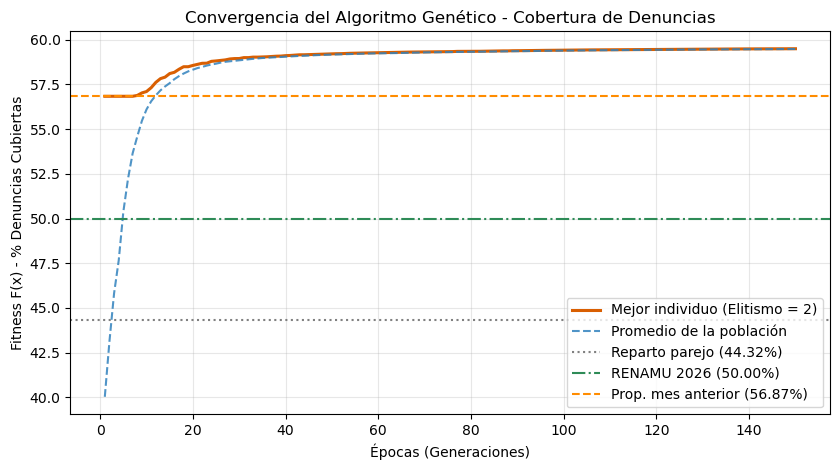

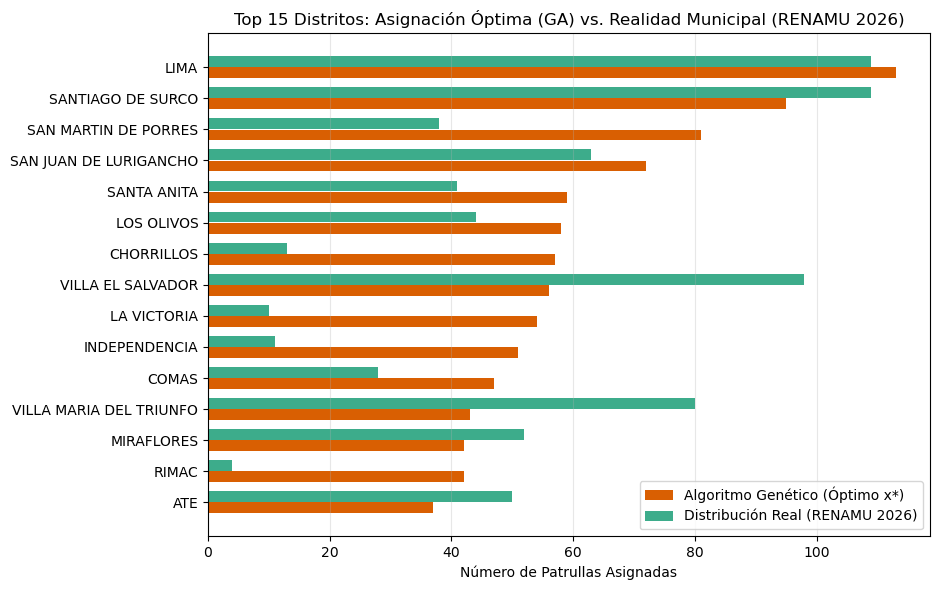

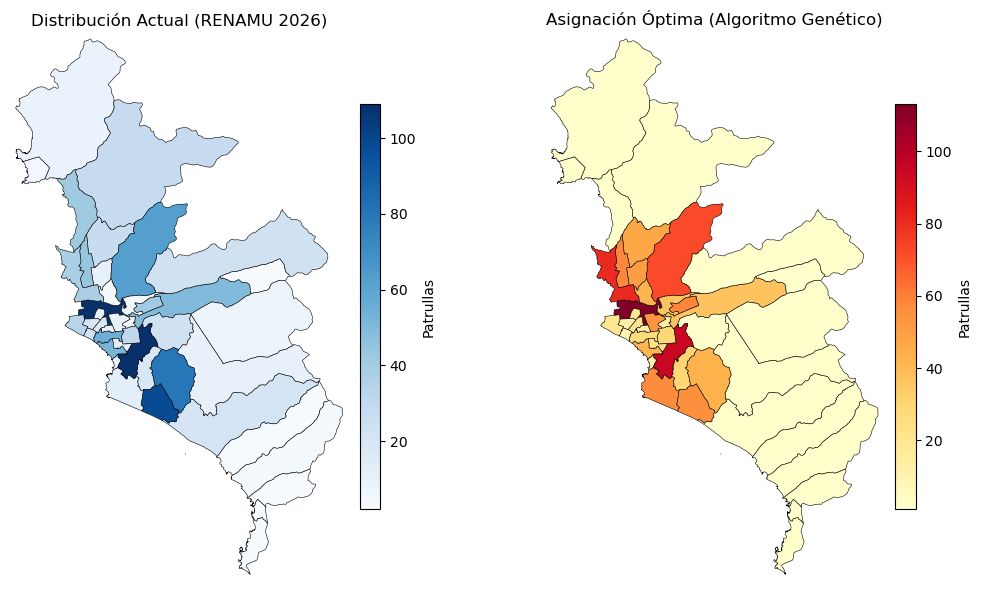

Mapa guardado correctamente en: ../outputs/figuras/04_ga_mapa_patrullas.png


In [25]:
# 1. Gráfica de convergencia del Algoritmo Genético
plt.figure(figsize=(8.5, 4.8))
plt.plot(range(1, epochs + 1), hist_mejor, label="Mejor individuo (Elitismo = 2)", linewidth=2.2, color="#d95f02")
plt.plot(range(1, epochs + 1), hist_prom, label="Promedio de la población", linestyle="--", color="#3182bd", alpha=0.85)
plt.axhline(fit_parejo, color="gray", linestyle=":", label=f"Reparto parejo ({fit_parejo:.2f}%)")
plt.axhline(fit_renamu, color="seagreen", linestyle="-.", label=f"RENAMU 2026 ({fit_renamu:.2f}%)")
plt.axhline(fit_prop_ant, color="darkorange", linestyle="--", label=f"Prop. mes anterior ({fit_prop_ant:.2f}%)")
plt.title("Convergencia del Algoritmo Genético - Cobertura de Denuncias")
plt.xlabel("Épocas (Generaciones)")
plt.ylabel("Fitness F(x) - % Denuncias Cubiertas")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/figuras/04_ga_convergencia.png", dpi=300)
plt.show()

# 2. Gráfica de barras: Top 15 Distritos con mayor asignación (GA vs RENAMU 2026)
top15 = df.sort_values("PATRULLAS_GA", ascending=True).tail(15)
y_pos = list(range(len(top15)))

plt.figure(figsize=(9.5, 6))
plt.barh([y - 0.18 for y in y_pos], top15["PATRULLAS_GA"], height=0.35, label="Algoritmo Genético (Óptimo x*)", color="#d95f02")
plt.barh([y + 0.18 for y in y_pos], top15["PATRULLAS_RENAMU"], height=0.35, label="Distribución Real (RENAMU 2026)", color="#1b9e77", alpha=0.85)
plt.yticks(y_pos, top15["DIST_NORM"])
plt.xlabel("Número de Patrullas Asignadas")
plt.title("Top 15 Distritos: Asignación Óptima (GA) vs. Realidad Municipal (RENAMU 2026)")
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/figuras/04_ga_top15_comparacion.png", dpi=300)
plt.show()

# 3. Mapa de patrullas dibujado directamente desde el archivo GeoJSON con json + matplotlib (sin geopandas)
ruta_geojson = "../data/osm/limites_distritos.geojson"
if os.path.exists(ruta_geojson):
    with open(ruta_geojson, "r", encoding="utf-8") as f:
        geo_data = json.load(f)
        
    # Diccionarios de búsqueda por UBIGEO y por nombre de distrito
    mapa_ga = {}
    mapa_ren = {}
    for i in range(len(df)):
        u = str(df.loc[i, "UBIGEO"]).strip().zfill(6)
        d_nom = str(df.loc[i, "DIST_NORM"]).strip().upper()
        mapa_ga[u] = df.loc[i, "PATRULLAS_GA"]
        mapa_ga[d_nom] = df.loc[i, "PATRULLAS_GA"]
        mapa_ren[u] = df.loc[i, "PATRULLAS_RENAMU"]
        mapa_ren[d_nom] = df.loc[i, "PATRULLAS_RENAMU"]

    def dibujar_mapa_propio (ax, geo_json, dict_valores, titulo, cmap_nombre):
        parches = []
        valores = []
        xs, ys = [], []
        for feat in geo_json.get("features", []):
            props = feat.get("properties", {})
            clave_u = str(props.get("UBIGEO", props.get("ubigeo", ""))).strip().zfill(6)
            clave_n = str(props.get("DIST_NORM", props.get("name", props.get("DISTRITO", "")))).strip().upper()
            val = dict_valores.get(clave_u, dict_valores.get(clave_n, 0))
            
            geom = feat.get("geometry", {})
            tipo = geom.get("type", "")
            coords = geom.get("coordinates", [])
            
            anillos = []
            if tipo == "Polygon":
                anillos = [coords[0]]
            elif tipo == "MultiPolygon":
                for poly in coords:
                    anillos.append(poly[0])
                    
            for anillo in anillos:
                pts = [(pt[0], pt[1]) for pt in anillo]
                for x, y in pts:
                    xs.append(x)
                    ys.append(y)
                parches.append(MplPolygon(pts, closed=True))
                valores.append(val)
                
        col = PatchCollection(parches, cmap=cmap_nombre, edgecolor="black", linewidth=0.4)
        col.set_array(np.array(valores))
        ax.add_collection(col)
        if len(xs) > 0 and len(ys) > 0:
            ax.set_xlim(min(xs) - 0.01, max(xs) + 0.01)
            ax.set_ylim(min(ys) - 0.01, max(ys) + 0.01)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(titulo)
        ax.axis("off")
        plt.colorbar(col, ax=ax, fraction=0.035, pad=0.02, label="Patrullas")

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    dibujar_mapa_propio(axes[0], geo_data, mapa_ren, "Distribución Actual (RENAMU 2026)", "Blues")
    dibujar_mapa_propio(axes[1], geo_data, mapa_ga, "Asignación Óptima (Algoritmo Genético)", "YlOrRd")
    plt.tight_layout()
    plt.savefig("../outputs/figuras/04_ga_mapa_patrullas.png", dpi=300)
    plt.show()
    print("Mapa guardado correctamente en: ../outputs/figuras/04_ga_mapa_patrullas.png")